<a href="https://colab.research.google.com/github/KeyHornO/Machine-Learning/blob/main/Week4_Assignment_Exploring_the_Mathematics_of_my_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descriptive Statistics, Covariance and Correlation
## Thermoelectric SnSe project

**Name:** Njuguna Benson  

**Course project repo:** https://github.com/KeyHornO/Machine-Learning

**Dataset:** the ESTM experimental thermoelectric database (Na & Chang, *npj Computational Materials*, 2022), imported from GitHub (`KRICT-DATA/SIMD`) in my previous notebook. I use the **SnSe-based materials** subset, which is the material family my project is about.

**Goal of this notebook:** summarise four numerical variables with basic statistics, measure how two of them are related, discuss whether correlation means causation, and write the simple idea *Input → Model → Output* as a mathematical expression.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/KRICT-DATA/SIMD/main/dataset/estm.xlsx"
estm = pd.read_excel(URL)
estm.columns = ["formula", "T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK", "pf_W_mK2", "zT", "doi"]

def is_snse_based(formula):
    """SnSe family: Sn and Se are >= 90% of atoms and Sn:Se is about 1:1."""
    if "(" in formula:
        return False
    amt = {}
    for el, n in re.findall(r"([A-Z][a-z]?)(\d*\.?\d*)", formula):
        amt[el] = amt.get(el, 0) + (float(n) if n else 1.0)
    sn, se, total = amt.get("Sn", 0), amt.get("Se", 0), sum(amt.values())
    return sn > 0 and se > 0 and (sn + se) / total >= 0.9 and 0.8 <= sn / se <= 1.25

snse = estm[estm["formula"].apply(is_snse_based)].reset_index(drop=True)
print("Full dataset:", estm.shape, "| SnSe-based subset:", snse.shape)
snse.head()

Full dataset: (5205, 8) | SnSe-based subset: (154, 8)


,formula,T_K,seebeck_uV_K,sigma_S_m,kappa_W_mK,pf_W_mK2,zT,doi
0,Sn0.98In0.02Se,373.0,391.0,35.0,0.800,0.000005,0.002495,https://doi.org/10.1016/j.jallcom.2016.01.190
1,Sn0.98In0.02Se,423.0,440.0,46.0,0.716,0.000009,0.005261,https://doi.org/10.1016/j.jallcom.2016.01.190
2,Sn0.98In0.02Se,473.0,472.0,58.0,0.670,0.000013,0.008000,https://doi.org/10.1016/j.jallcom.2016.01.190
3,Sn0.98In0.02Se,523.0,492.0,70.0,0.631,0.000017,0.014044,https://doi.org/10.1016/j.jallcom.2016.01.190
4,Sn0.98In0.02Se,573.0,502.0,90.0,0.620,0.000023,0.019000,https://doi.org/10.1016/j.jallcom.2016.01.190


## 1. Selected variables

| Variable | Meaning | Why it matters for my project |
|---|---|---|
| `T_K` | Measurement temperature (K) | Thermoelectric performance changes strongly with temperature |
| `seebeck_uV_K` | Seebeck coefficient (µV/K) | Voltage generated per kelvin; part of the power factor |
| `kappa_W_mK` | Thermal conductivity (W/m·K) | Low values are needed for high efficiency |
| `zT` | Figure of merit (dimensionless) | The main performance measure, and my likely ML target |

In [2]:
variables = ["T_K", "seebeck_uV_K", "kappa_W_mK", "zT"]
data = snse[variables]
print("Missing values per column:\n", data.isna().sum())

Missing values per column:
 T_K             0
seebeck_uV_K    0
kappa_W_mK      0
zT              0
dtype: int64


## 2. Mean, median, range, variance and standard deviation
Variance and standard deviation are the **sample** versions (divide by n − 1), which is the pandas default.

In [3]:
stats = pd.DataFrame({
    col: {
        "mean":     data[col].mean(),
        "median":   data[col].median(),
        "min":      data[col].min(),
        "max":      data[col].max(),
        "range":    data[col].max() - data[col].min(),
        "variance": data[col].var(),
        "std dev":  data[col].std(),
    }
    for col in variables
}).T
stats.round(3)

,mean,median,min,max,range,variance,std dev
T_K,563.747,573.000,300.000,873.000,573.000,29693.301,172.317
seebeck_uV_K,387.905,384.000,168.040,605.360,437.320,7454.342,86.339
kappa_W_mK,0.665,0.620,0.116,2.332,2.216,0.123,0.351
zT,0.366,0.211,0.000,2.158,2.157,0.187,0.433


## 3. Covariance and correlation for two variables
I choose **temperature (`T_K`)** and **zT**, because I want to know whether zT is associated with temperature.

In [4]:
x, y = snse["T_K"], snse["zT"]

cov_xy = np.cov(x, y, ddof=1)[0, 1]      # sample covariance
corr_xy = np.corrcoef(x, y)[0, 1]        # Pearson correlation

print(f"Covariance (T_K, zT):          {cov_xy:.3f}")
print(f"Pearson correlation (T_K, zT): {corr_xy:.3f}")

# cross-check with pandas
print("pandas check:", round(x.cov(y), 3), round(x.corr(y), 3))

Covariance (T_K, zT):          54.746
Pearson correlation (T_K, zT): 0.734
pandas check: 54.746 0.734


## 4. Plot: zT versus temperature

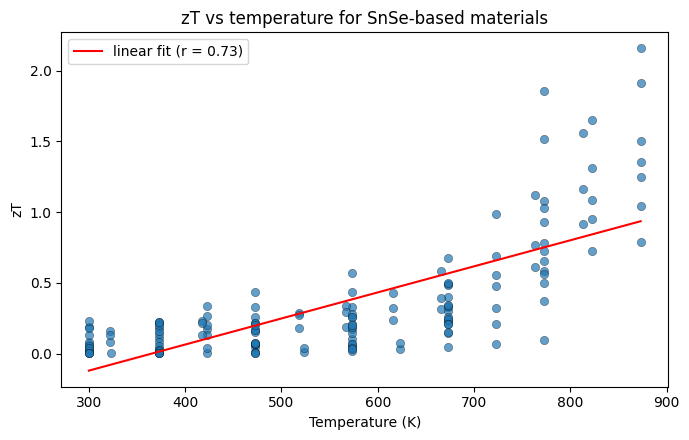

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(snse["T_K"], snse["zT"], alpha=0.7, edgecolor="k", linewidth=0.3)

# straight-line fit to show the overall trend
slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, slope * xs + intercept, color="red", label=f"linear fit (r = {corr_xy:.2f})")

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("zT")
ax.set_title("zT vs temperature for SnSe-based materials")
ax.legend()
plt.tight_layout()
plt.show()

## 5. What the results tell me

**What do the statistics tell me about the data?**
- The data covers 154 measurements of SnSe-based materials from 6 papers, across temperatures from 300 K to 873 K. The mean temperature (about 564 K) is close to the median (573 K), so the temperature coverage is fairly even.
- **zT is strongly right-skewed.** Its mean (about 0.37) is well above its median (about 0.21), and its standard deviation (about 0.43) is larger than the mean. Most measurements have low zT, and a few high-temperature measurements reach above 2. The range is about 2.16.
- **Thermal conductivity is low overall**, with a mean of about 0.66 W/m·K and a median of about 0.62, which is consistent with SnSe being a good thermoelectric candidate. A few values reach 2.3, so this variable is also slightly skewed.
- The Seebeck coefficient is large (mean about 388 µV/K) and more symmetric (mean about equal to median).
- Variances cannot be compared across variables because each has different units and scales; the standard deviation relative to the mean is the better guide to spread.

**What does the correlation tell me about the relationship?**
- The covariance is positive (about 54.7), so zT tends to increase as temperature increases. Covariance depends on the units, so its size alone is hard to interpret.
- The Pearson correlation is about **0.73**, a **strong positive** relationship. Higher temperature goes with higher zT, which matches what is known for SnSe, where performance is best at high temperature.
- **Cautions:** correlation does not prove that temperature alone causes the change. The relationship is not a straight line: grouping the data by temperature shows zT stays low until about 600 K and then rises sharply above about 750 K, so the linear fit is only a rough summary. Also, the 154 rows come from only 6 papers and 16 compositions, so the points are not fully independent, and the correlation is likely overstated.
- **For my ML project:** temperature is an important input feature, but it should be combined with composition and processing variables, and models need non-linear methods and validation that keeps papers (or samples) separate.

**Does correlation necessarily mean that one variable causes the other?**
No. A correlation only says that two variables move together. It does not say that one produces the change in the other. Here there is a good physical reason to believe temperature really does influence zT, because carrier excitation and phonon scattering both change with temperature, and the ESTM data itself comes from measurements taken at several temperatures on the same materials. But the correlation by itself does not prove this. Other factors could also create or distort a correlation: a third variable (for example, the best-performing materials may simply have been measured up to higher temperatures than the weaker ones), differences between the 6 papers, or coincidence in a small dataset. Establishing cause requires a controlled experiment or a physical model, not a correlation coefficient alone.

## 6. Input → Function/Model → Output

I choose **temperature as the input** and **zT as the output**:

- Input: $x = T$ (temperature in K)
- Output: $y = zT$

The general idea of any ML model is

$$ x \;\longrightarrow\; f(\cdot) \;\longrightarrow\; y \qquad\text{i.e.}\qquad zT = f(T) $$

The simplest choice for the function $f$ is a straight line with two parameters, $\beta_0$ (intercept) and $\beta_1$ (slope):

$$ \widehat{zT} = f(T) = \beta_0 + \beta_1\, T $$

"Learning" means choosing $\beta_0$ and $\beta_1$ so that the predicted $\widehat{zT}$ is as close as possible to the measured zT, by minimising the squared error

$$ \text{error} = \frac{1}{n}\sum_{i=1}^{n}\left(zT_i - \widehat{zT}_i\right)^2 $$

In [6]:
# Fit the simple model zT = b0 + b1 * T  (least squares)
b1, b0 = np.polyfit(snse["T_K"], snse["zT"], 1)

def model(T):
    """f(T): the model that maps the input (temperature) to the output (predicted zT)."""
    return b0 + b1 * np.asarray(T, dtype=float)

print(f"Fitted model:  zT_hat = {b0:.3f} + {b1:.5f} * T")

# Input -> model -> output for a few temperatures
inputs = np.array([300, 500, 700, 850])
table = pd.DataFrame({"input T (K)": inputs, "model output zT_hat": model(inputs).round(3)})
display(table)

# How good is it?
pred = model(snse["T_K"])
rmse = np.sqrt(((snse["zT"] - pred) ** 2).mean())
r2 = np.corrcoef(snse["T_K"], snse["zT"])[0, 1] ** 2
print(f"R-squared = {r2:.2f}   RMSE = {rmse:.2f}")

Fitted model:  zT_hat = -0.674 + 0.00184 * T


,input T (K),model output zT_hat
0,300,-0.121
1,500,0.248
2,700,0.617
3,850,0.893


R-squared = 0.54   RMSE = 0.29


### What this simple model shows
- The model turns an input (temperature) into an output (predicted zT): for example, at 700 K it predicts a zT of about 0.62.
- It explains only part of the variation (R² ≈ 0.54, so about 54% of the variance in zT). The rest depends on other inputs, such as composition and processing.
- It is **too simple**: it predicts a negative zT at 300 K (which is physically impossible) and underpredicts at 850 K, because the real relationship is curved. This is why a project like mine needs **more input features** (composition, texture, grain size) and a more flexible model than a straight line.
- Each variable I add becomes another input $x_j$, so the general form becomes $zT = f(x_1, x_2, \dots, x_k)$ — which is exactly what a machine learning model learns from data.